* 1）计划线路可能与实际不符，即发运异常；
* 2）未涵盖部分未下单的货量；
* 3）已下单的货量可能会取消。在得到一条线路的总货量后，需要将其拆分至 10
分钟的颗粒度，从而更好地辅助后续优化决策步骤。
* 4） 短途运输场景每车次可装载
的包裹量是相对固定的，因此车次可以直接由货量转化得到
* 5）10分钟颗粒度的累计货量达到车辆满载量，即可发运。
* 6）对部分临近的线路，若包裹量较少，或整车发运后剩余不足一车的货量，将多个线路的货量合并为一车发运，这种场景称为“串
点”，一般从同一起始场地出发运送到不同的目的站点。串点涉及的线路一般不允许超过 3 个。
* 7）自有车辆周转的前提是前后的运输需求可衔接，具体标准是：前一个需求的发运时间+装车时间+在途时间*2+卸车时间<后一个需求的发运时间。
* 8）对于剩余自有车辆无法承运的运输
需求，由外部承运商进行运输，但成本会较高。

####  以上逻辑的示意图如图1所示，根据货量该线路存在3个运输需求，假设该线路的最晚发车时间为5:00，则最后一个需求的发运时间为5:00，其余需求的发运时间为1:00和3:00，均根据货量折算得到。假设需求1使用自有车1；对于需求2，自有车1完成需求1后返回到分拣中心的时间为4:30，无法继续发运需求2，若此时无剩余的自有车，则需求2需使用外部车进行发运；对于需求3，由于自有车1返回后时间早于需求3的发运时间，则可以继续使用自有车1发运需求3
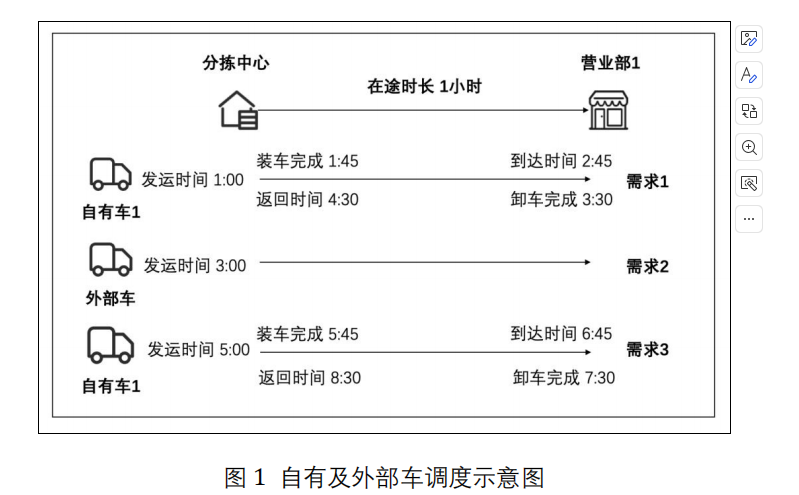

#### 评价指标包括效率和成本
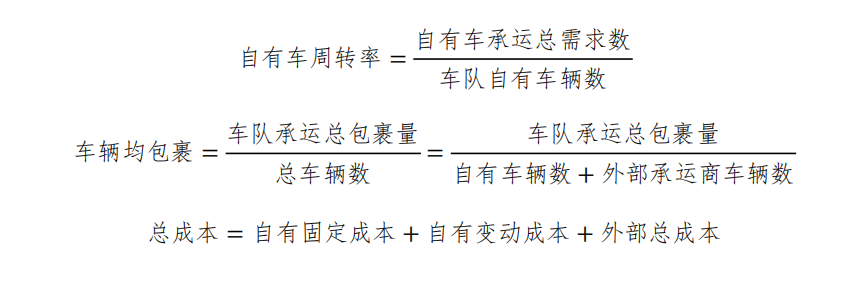

* 假设串点的车队必须送达站点返回后,在清点货物后继续发往其他站点
* 假设串点不需要重新装卸货物

####   问题 2：根据问题 1 输出的结果，确定运输需求，包括每条线路 的发运车辆数、预计发运时间及串点方案，其中每个需求的发运时间 不能晚于线路的发运节点。基于以上结果，确定每个需求的承运车辆； 要求自有车的周转率尽可能高，以及所有车辆均包裹尽可能高、总成 本尽可能低。请将结果写入结果表 3 中，结果需包含：线路编码、预 计发运时间、承运车辆。其中串点方案可将多条线路编码合并在“线 路”一列展示，无法使用自有车满足时注明为“外部” ，并在论文 中给出线路编码为“场地 3 - 站点 83 – 0600”和“场地 3 - 站点 83 – 1400”的调度结果。

In [1]:
## 导入会使用到的库
import pandas as pd

In [2]:
df1 = pd.read_excel('附件1.xlsx')
df2 = pd.read_excel('附件2.xlsx')
df3 = pd.read_excel('附件3.xlsx')
df4 = pd.read_excel('附件4.xlsx')
df5 = pd.read_excel('附件5.xlsx')
df1

,线路编码,起始场地,目的场地,发运节点,车队编码,在途时长,自有变动成本,外部承运商成本
0,场地1 - 站点1 - 1400,场地1,站点1,14:00:00,车队1,1.02,62,129
1,场地1 - 站点1 - 0600,场地1,站点1,06:00:00,车队1,1.02,62,207
2,场地1 - 站点2 - 1400,场地1,站点2,14:00:00,车队1,1.50,89,201
3,场地1 - 站点3 - 1400,场地1,站点3,14:00:00,车队1,1.33,79,279
4,场地1 - 站点3 - 0600,场地1,站点3,06:00:00,车队1,1.25,79,303
...,...,...,...,...,...,...,...,...
275,场地4 - 站点139 - 1400,场地4,站点139,14:00:00,车队5,0.69,53,168
276,场地4 - 站点139 - 0600,场地4,站点139,06:00:00,车队5,0.69,53,152
277,场地4 - 站点140 - 0600,场地4,站点140,06:00:00,车队5,0.47,43,101
278,场地4 - 站点138 - 1400,场地4,站点138,14:00:00,车队5,0.36,39,131


#### 对于这个问题，我们应该是按发运节点和每一天拆成一个一个的车辆分配方案，例如，对于2024年12月1日的车辆分配方案，我们需要捕捉到11月30日21:00的订货数据到12月1日21:00的订货流情况，而由于不同车队负责不同站点之间的配送，我们只需要一个车队一个车队的确定优化方案。而由于早班必须全部在六点发车，因此到了晚班11点开始出现订货量时，所有的车辆都已经回来了。因此，应当遍历每个日期的每个车队的每个发运节点，对当前日期的当前车队进行问题的解析、

In [3]:
import datetime
df = pd.merge(df2,df1,on='线路编码',how='left')
df = df[['线路编码', '日期', '分钟起始','发运节点', '包裹量', '车队编码', '在途时长',
       '自有变动成本', '外部承运商成本']]
df['时间'] = pd.to_datetime(df['日期'].astype('str')+' '+df['分钟起始'].astype('str'))

for i in df['日期'].unique():
    year = int(str(i).split('-')[0])
    month = int(str(i).split('-')[1])
    day = int(str(i).split('-')[2][:2])
    for o in df['车队编码'].unique():
        for b in df['发运节点'].unique():
            if b == datetime.time(6, 0):
                start_time = datetime.datetime(year, month, day,21,00) - datetime.timedelta(days=1)
                end_time = datetime.datetime(year, month, day,6,00)
                tem = df[(df.时间>=start_time)&(df.时间<=end_time) & (df.车队编码==o) & (df.发运节点==b)]
            else:
                start_time = datetime.datetime(year, month, day,11,00)
                end_time = datetime.datetime(year, month, day,14,00)
                tem = df[(df.时间>=start_time)&(df.时间<=end_time) & (df.车队编码==o) & (df.发运节点==b)]

#### 可以将站点想象成水桶，多个水桶随着时间逐步蓄水，然后满额时就倒掉，然后再次蓄水。因此，最直接的车辆分配方案，应当是满足订货量满额即配送的原则，然后，肯定所有的站点在截止时应该都会有一些残余货量，这个时候就需要考虑，到底是将这个残余货量进行单独配送还是串点配送，一般来说，我们默认串点配送。如果有车，需要满足自有车辆优先配送的原则

#### 而由于题目给出了默认的装车时间，所以在货量未满1000时，我们并不知道多久才会满额，所以，我们假设是否配送车辆的决策需要再货量满额时进行决策，然后再计算装车时间。

#### 整个过程可以按照如下的方式进行：假设我有20辆车，每辆车的载货量为1000，装车及卸车时长均为45分钟。我的车辆需要从我的场地发往不同的站点，每个站点的货物量是单独计算的。对于一批按时间的订单货物流（昨天的21:00到今天早上的6:00），如果站点的累积货物量达到了1000，则进行配送，在该时间截点多出来的货物量继续放到下个时间流中进行累积。需要知道的是，对于当前车辆的下次可以配送的时间点为:发运时间+装车时间+在途时间*2+卸车时间，如果可配送时间点＜发货时间，则可以用该车辆配送。所有的货物都必须在6:00前全部发车完毕，无论是否是满载的。而如果某个时间点没有可用车辆了，则进行外部配送。

## 基于简单配送的车辆分配方案（不包括串点）

In [4]:
import pandas as pd
from datetime import datetime, timedelta

# 定义外部配送处理
def handle_external_delivery(cargo_amount, cargo_time, station):
    print(f"At {cargo_time.strftime('%Y-%m-%d %H:%M:%S')}, external delivery required for {cargo_amount} units to {station}.")

# 车辆配送安排函数
def plan_delivery(code,cost,total_vehicles,vehicle_capacity,loading_time,unloading_time,vehicles,start_time,end_time,cargo_flow,cargo_go_num):
    deliveries = []

    n = 0 #自有车总需求数
    # 按照时间流从早到晚遍历
    k = 0 #外部车辆数
    current_time = start_time
    while current_time <= end_time:
        # 对每个站点进行货物累积
        for station, station_cargo in cargo_flow.items():
            accumulated_cargo = 0
            # 累积当前时间点之前的所有货物量
            for cargo_time, cargo_amount in station_cargo.items():
                if cargo_time <= current_time:
                    accumulated_cargo += cargo_amount
                if cargo_time == current_time:
                    break
            
            # 计算当前时间点的可用车辆
            available_vehicles = [v for v in vehicles if v["next_available_time"] <= current_time]
            
      
            # 尝试分配车辆
            #代码逻辑问题:如果该站点没有进行过配送,则只需要大于1000即可,否则,如果配送过1次,则需要大于2000
            if accumulated_cargo >= 1000 + cargo_go_num[station]*1000 and available_vehicles:
                #每个站点已经配送过的次数需要+1
                cargo_go_num[station] += 1
                
                delivery_vehicle = available_vehicles.pop(0)
                # 车辆配送时长：装车时间 + 在途时间*2 + 卸车时间
                vehicle_delivery_time = current_time + loading_time + timedelta(minutes=10) * 2 + unloading_time
                deliveries.append({
                    "vehicle_id": delivery_vehicle["id"],
                    "station": station,
                    "cargo_time": current_time,
                    "delivery_time": vehicle_delivery_time,
                    "cargo_delivered": 1000,
                    "cost": cost[station][0]
                })
                
                # 更新车辆下次可用时间
                delivery_vehicle["next_available_time"] = vehicle_delivery_time
                vehicles[delivery_vehicle['id']] = delivery_vehicle
                n+=1
            # 如果没有可用车辆，则进行外部配送
            elif accumulated_cargo >= 1000 + cargo_go_num[station]*1000 and not available_vehicles:
                deliveries.append({
                    "vehicle_id": 999,
                    "station": station,
                    "cargo_time": current_time,
                    "delivery_time": vehicle_delivery_time,
                    "cargo_delivered": 1000,
                    "cost": cost[station][1]
                })                
                #每个站点已经配送过的次数需要+1
                cargo_go_num[station] += 1
                n+=1
                k+=1
            # 如果货流结尾还剩余货物，即使没有满足满载也同样需要进行配送
            available_vehicles = [v for v in vehicles if v["next_available_time"] <= current_time]
            if accumulated_cargo > cargo_go_num[station]*1000 and cargo_time == list(station_cargo.keys())[-1] and available_vehicles:
                
                delivery_vehicle = available_vehicles.pop(0)
                # 车辆配送时长：装车时间 + 在途时间*2 + 卸车时间
                vehicle_delivery_time = current_time + loading_time + timedelta(minutes=10) * 2 + unloading_time
                deliveries.append({
                    "vehicle_id": delivery_vehicle["id"],
                    "station": station,
                    "cargo_time": current_time,
                    "delivery_time": vehicle_delivery_time,
                    "cargo_delivered": accumulated_cargo- cargo_go_num[station]*1000,
                    "cost": cost[station][0]
                })
                n+=1
                # 更新车辆下次可用时间
                delivery_vehicle["next_available_time"] = vehicle_delivery_time
                vehicles[delivery_vehicle['id']] = delivery_vehicle
            elif accumulated_cargo > cargo_go_num[station]*1000 and cargo_time == list(station_cargo.keys())[-1] and not available_vehicles:
                deliveries.append({
                    "vehicle_id": 999,
                    "station": station,
                    "cargo_time": current_time,
                    "delivery_time": vehicle_delivery_time,
                    "cargo_delivered": accumulated_cargo- cargo_go_num[station]*1000,
                    "cost": cost[station][1]
                })        # 移动到下一个时间点
                n+=1
                k+=1
        current_time += timedelta(minutes=10)

    # 输出配送计划
    delivery_df = pd.DataFrame(deliveries)
    delivery_df['车队编码'] = code
    return delivery_df
def main(tem):
    tem = tem.sort_values(by='时间')
    # 初始化数据
    total_vehicles = df5[df5.车队编码==tem['车队编码'].values[0]]['自有车数量'].values[0]
    vehicle_capacity = 1000  # 每辆车的载货量
    loading_time = timedelta(minutes=45)  # 装车时间
    unloading_time = timedelta(minutes=45)  # 卸车时间
    
    # 假设车辆的初始状态
    vehicles = [{"id": i, "next_available_time": tem['时间'].values[0].astype('datetime64[ms]').tolist()} for i in range(0, total_vehicles + 1)]
    
    # 假设时间流
    start_time = tem['时间'].values[0].astype('datetime64[ms]').tolist()  # 昨天的21:00
    end_time = tem['时间'].values[-1].astype('datetime64[ms]').tolist()  # 今天的6:00
    
    # 假设多个站点的货物需求
    cargo_flow = {}
    cargo_go_num = {}
    cost = {} #成本核算
    for i in tem['线路编码'].unique():
        t = tem[tem.线路编码==i]
        dic = {}
        for n,m in zip(t['时间'].values,t['包裹量'].values):
            dic[n.astype('datetime64[ms]').tolist()] = m
        cargo_flow[i] = dic
        cost[i] = t[['自有变动成本','外部承运商成本']].values[0].tolist()
        cargo_go_num[i] = 0
    code = tem['车队编码'].values[0]
    return plan_delivery(code,cost,total_vehicles,vehicle_capacity,loading_time,unloading_time,vehicles,start_time,end_time,cargo_flow,cargo_go_num)

In [5]:
import datetime

u = pd.read_excel('结果表2.xlsx')
df22 = pd.concat([df2,u])

df = pd.merge(df22,df1,on='线路编码',how='left')
df = df[['线路编码', '日期', '分钟起始','发运节点', '包裹量', '车队编码', '在途时长',
       '自有变动成本', '外部承运商成本']]
df['时间'] = pd.to_datetime(df['日期'].astype('str')+' '+df['分钟起始'].astype('str'))

result = pd.DataFrame()

for i in df['日期'].unique():
    ddd = i
    year = int(str(i).split('-')[0])
    month = int(str(i).split('-')[1])
    day = int(str(i).split('-')[2][:2])
    for o in df['车队编码'].unique():
        for b in df['发运节点'].unique():
            if b == datetime.time(6, 0):
                start_time = datetime.datetime(year, month, day,21,00) - datetime.timedelta(days=1)
                end_time = datetime.datetime(year, month, day,6,00)
                tem = df[(df.时间>=start_time)&(df.时间<=end_time) & (df.车队编码==o) & (df.发运节点==b)]
            else:
                start_time = datetime.datetime(year, month, day,11,00)
                end_time = datetime.datetime(year, month, day,14,00)
                tem = df[(df.时间>=start_time)&(df.时间<=end_time) & (df.车队编码==o) & (df.发运节点==b)]
            if not tem.empty:
                subresult = main(tem)
                subresult['日期'] = ddd
      
                result = pd.concat([result,subresult])
result.to_excel('分配结果.xlsx')
result

,vehicle_id,station,cargo_time,delivery_time,cargo_delivered,cost,车队编码,日期
0,0,场地3 - 站点57 - 0600,2024-11-30 22:40:00,2024-12-01 00:30:00,1000.000000,54,车队3,2024-12-01
1,1,场地3 - 站点83 - 0600,2024-11-30 22:50:00,2024-12-01 00:40:00,1000.000000,60,车队3,2024-12-01
2,2,场地3 - 站点94 - 0600,2024-11-30 23:00:00,2024-12-01 00:50:00,1000.000000,57,车队3,2024-12-01
3,3,场地3 - 站点63 - 0600,2024-11-30 23:10:00,2024-12-01 01:00:00,1000.000000,52,车队3,2024-12-01
4,4,场地3 - 站点74 - 0600,2024-11-30 23:10:00,2024-12-01 01:00:00,1000.000000,41,车队3,2024-12-01
...,...,...,...,...,...,...,...,...
23,999,场地2 - 站点50 - 1400,2024-12-16 13:50:00,2024-12-16 15:40:00,800.585613,182,车队2,2024-12-16
24,999,场地2 - 站点38 - 1400,2024-12-16 13:50:00,2024-12-16 15:40:00,363.418272,243,车队2,2024-12-16
25,999,场地2 - 站点46 - 1400,2024-12-16 13:50:00,2024-12-16 15:40:00,1000.000000,256,车队2,2024-12-16
26,999,场地2 - 站点46 - 1400,2024-12-16 13:50:00,2024-12-16 15:40:00,45.167125,256,车队2,2024-12-16


In [6]:
n1 = []
n2 = []
n3 = []
date = []
c = []
for i in result['日期'].unique():
    print(i)
    for o in result['车队编码'].unique():
        tem = result[(result.日期==i)&(result.车队编码==o)]
        
        total_vehicles = df5[df5.车队编码==o]['自有车数量'].values[0]
        n = len(tem[tem.vehicle_id!=999])

        #自有车周转率
        n1.append(n/total_vehicles)
        #车辆均包裹 
        total_delivered = tem['cargo_delivered'].sum()
        n2.append(total_delivered/(total_vehicles+len(tem[tem.vehicle_id==999])))
        #总成本
        price1 = df1[df1.车队编码==o]['自有变动成本'].values[0]
        price2 = df1[df1.车队编码==o]['外部承运商成本'].values[0]
        date.append(i)
        n3.append(total_vehicles*100+price1*len(tem[tem.vehicle_id!=999])+price2*len(tem[tem.vehicle_id==999]))
        c.append(o)
result2 = pd.DataFrame({'日期':date,'车队':c,'自有车周转率':n1,'车辆均包裹':n2,'总成本':n3})
result2.to_excel('问题2\\成本核算（不同车队不同日期）.xlsx')

total_result = result2.groupby(['日期']).agg({
    '自有车周转率': 'mean',  # 对 x1 列进行 mean 聚合
    '车辆均包裹': 'mean',  # 对 x2 列进行 mean 聚合
    '总成本': 'sum'    # 对 x3 列进行 sum 聚合
})
total_result.to_excel('问题2\\成本核算.xlsx')

2024-12-01 00:00:00
2024-12-02 00:00:00
2024-12-03 00:00:00
2024-12-04 00:00:00
2024-12-05 00:00:00
2024-12-06 00:00:00
2024-12-07 00:00:00
2024-12-08 00:00:00
2024-12-09 00:00:00
2024-12-10 00:00:00
2024-12-11 00:00:00
2024-12-12 00:00:00
2024-12-13 00:00:00
2024-12-14 00:00:00
2024-12-15 00:00:00
2024-12-16 00:00:00


#### 建模函数

In [78]:
from collections import defaultdict

def minimal_vehicles_with_assignment(sites, weights, edges):
    
    graph = defaultdict(list)
    for u, v in edges:
        graph[u].append(v)
        graph[v].append(u)
    
  
    for site in sites:
        if site not in weights:
            weights[site] = 0  
    
    
    all_sites_in_edges = set()
    for u, v in edges:
        all_sites_in_edges.add(u)
        all_sites_in_edges.add(v)
    
    isolated_sites = [site for site in sites if site not in all_sites_in_edges]
    connected_sites = [site for site in sites if site in all_sites_in_edges]
    
    
    sorted_connected_sites = sorted(connected_sites, key=lambda x: -weights[x])
    visited = set()
    assignments = []
    
    for site in sorted_connected_sites:
        if site in visited:
            continue
        current_vehicle = [site]
        current_weight = weights[site]
        visited.add(site)
        
        for neighbor in sorted(graph[site], key=lambda x: -weights[x]):
            if (
                neighbor not in visited
                and weights[neighbor] + current_weight <= 1000
                and len(current_vehicle) < 3
            ):
                current_vehicle.append(neighbor)
                current_weight += weights[neighbor]
                visited.add(neighbor)
        
        assignments.append(current_vehicle)
    
  
    for site in isolated_sites:
        assignments.append([site])
    
    total_vehicles = len(assignments)
    return total_vehicles, assignments


sites = ['A', 'B', 'C', 'D']
weights = {'A': 300, 'B': 400, 'C': 500, 'D': 200}
edges = [('A', 'B'), ('B', 'C'), ('C', 'D')]

total_vehicles, assignments = minimal_vehicles_with_assignment(sites, weights, edges)
print(f"Total vehicles needed: {total_vehicles}")
for i, vehicle in enumerate(assignments, 1):
    print(f"Vehicle {i}: Delivers to {vehicle} with total weight {sum(weights[site] for site in vehicle)}")

Total vehicles needed: 3
Vehicle 1: Delivers to ['C', 'B'] with total weight 900
Vehicle 2: Delivers to ['A'] with total weight 300
Vehicle 3: Delivers to ['D'] with total weight 200


## 基于复杂配送的车辆分配方案（包括串点）

In [82]:
def plan_delivery(code,cost,total_vehicles,vehicle_capacity,loading_time,unloading_time,vehicles,start_time,end_time,cargo_flow,cargo_go_num):
    deliveries = []

    n = 0 #自有车总需求数
    # 按照时间流从早到晚遍历
    k = 0 #外部车辆数
    current_time = start_time
    #配送站点
    sites = []
    #每个站点的需求
    weights = {}
    while current_time <= end_time:
        # 对每个站点进行货物累积
        for station, station_cargo in cargo_flow.items():
            accumulated_cargo = 0
            # 累积当前时间点之前的所有货物量
            for cargo_time, cargo_amount in station_cargo.items():
                if cargo_time <= current_time:
                    accumulated_cargo += cargo_amount
                if cargo_time == current_time:
                    break
            
            # 计算当前时间点的可用车辆
            available_vehicles = [v for v in vehicles if v["next_available_time"] <= current_time]
            
      
            
            #代码逻辑问题:如果该站点没有进行过配送,则只需要大于1000即可,否则,如果配送过1次,则需要大于2000
            if accumulated_cargo >= 1000 + cargo_go_num[station]*1000 and available_vehicles:
                #每个站点已经配送过的次数需要+1
                cargo_go_num[station] += 1
                
                delivery_vehicle = available_vehicles.pop(0)
                # 车辆配送时长：装车时间 + 在途时间*2 + 卸车时间
                vehicle_delivery_time = current_time + loading_time + timedelta(minutes=10) * 2 + unloading_time
                deliveries.append({
                    "vehicle_id": delivery_vehicle["id"],
                    "station": station,
                    "cargo_time": current_time,
                    "delivery_time": vehicle_delivery_time,
                    "cargo_delivered": 1000,
                    "cost": cost[station][0],
                        "multi":0
                })
                
                # 更新车辆下次可用时间
                delivery_vehicle["next_available_time"] = vehicle_delivery_time
                vehicles[delivery_vehicle['id']] = delivery_vehicle
                n+=1
            # 如果没有可用车辆，则进行外部配送
            elif accumulated_cargo >= 1000 + cargo_go_num[station]*1000 and not available_vehicles:
                deliveries.append({
                    "vehicle_id": 999,
                    "station": station,
                    "cargo_time": current_time,
                    "delivery_time": vehicle_delivery_time,
                    "cargo_delivered": 1000,
                    "cost": cost[station][1],
                        "multi":0
                })                
                #每个站点已经配送过的次数需要+1
                cargo_go_num[station] += 1
                n+=1
                k+=1
            # 如果货流结尾还剩余货物，即使没有满足满载也同样需要进行配送
            available_vehicles = [v for v in vehicles if v["next_available_time"] <= current_time]
            if accumulated_cargo > cargo_go_num[station]*1000 and cargo_time == list(station_cargo.keys())[-1]:
                sites.append(station.split(' ')[2])
                weights[station.split(' ')[2]] = accumulated_cargo - cargo_go_num[station]*1000
        available_vehicles = [v for v in vehicles if v["next_available_time"] <= current_time]
        edges = []
        for i,o in zip(df4.站点编号1,df4.站点编号2):
            edges.append((i,o))
        edges = [(u, v) for u, v in edges if u in weights.keys() and v in weights.keys()]
        if current_time == end_time:
            #串点运送
            assignments = minimal_vehicles_with_assignment(sites, weights, edges)[1]
            if len(available_vehicles)>=len(assignments):
                for ttt in range(len(assignments)):
                    delivery_vehicle = available_vehicles.pop(0)
                    # 车辆配送时长：装车时间 + 在途时间*2 + 卸车时间
                    vehicle_delivery_time = current_time + loading_time + timedelta(minutes=10) * 2 + unloading_time
                    deliveries.append({
                        "vehicle_id": delivery_vehicle["id"],
                        "station": '-'.join(assignments[ttt]),
                        "cargo_time": current_time,
                        "delivery_time": vehicle_delivery_time,
                        "cargo_delivered": sum(weights[site] for site in assignments[ttt]),
                        "cost": cost[station][0],
                        "multi":1
                    })               
                    # 更新车辆下次可用时间
                    delivery_vehicle["next_available_time"] = vehicle_delivery_time
                    vehicles[delivery_vehicle['id']] = delivery_vehicle
            else:
                for ttt in range(len(assignments)):
                    if ttt+1 <= len(available_vehicles):
                        delivery_vehicle = available_vehicles.pop(0)
                        # 车辆配送时长：装车时间 + 在途时间*2 + 卸车时间
                        vehicle_delivery_time = current_time + loading_time + timedelta(minutes=10) * 2 + unloading_time
                        deliveries.append({
                            "vehicle_id": delivery_vehicle["id"],
                            "station": '-'.join(assignments[ttt]),
                            "cargo_time": current_time,
                            "delivery_time": vehicle_delivery_time,
                            "cargo_delivered": sum(weights[site] for site in assignments[ttt]),
                            "cost": cost[station][0],
                            "multi":1
                        })               
                        # 更新车辆下次可用时间
                        delivery_vehicle["next_available_time"] = vehicle_delivery_time
                        vehicles[delivery_vehicle['id']] = delivery_vehicle
                    else:
                        deliveries.append({
                            "vehicle_id": 999,
                            "station": '-'.join(assignments[ttt]),
                            "cargo_time": current_time,
                            "delivery_time": vehicle_delivery_time,
                            "cargo_delivered": sum(weights[site] for site in assignments[ttt]),
                            "cost": cost[station][0],
                            "multi":1
                        })     
        current_time += timedelta(minutes=10)

    # 输出配送计划
    delivery_df = pd.DataFrame(deliveries)
    delivery_df['车队编码'] = code
    return delivery_df

In [83]:
import datetime

u = pd.read_excel('问题1\\结果表2.xlsx')
df22 = pd.concat([df2,u])

df = pd.merge(df22,df1,on='线路编码',how='left')
df = df[['线路编码', '日期', '分钟起始','发运节点', '包裹量', '车队编码', '在途时长',
       '自有变动成本', '外部承运商成本']]
df['时间'] = pd.to_datetime(df['日期'].astype('str')+' '+df['分钟起始'].astype('str'))

chuan_result = pd.DataFrame()



for i in df['日期'].unique():
    ddd = i
    year = int(str(i).split('-')[0])
    month = int(str(i).split('-')[1])
    day = int(str(i).split('-')[2][:2])
    for o in df['车队编码'].unique():
        for b in df['发运节点'].unique():
            if b == datetime.time(6, 0):
                start_time = datetime.datetime(year, month, day,21,00) - datetime.timedelta(days=1)
                end_time = datetime.datetime(year, month, day,6,00)
                tem = df[(df.时间>=start_time)&(df.时间<=end_time) & (df.车队编码==o) & (df.发运节点==b)]
            else:
                start_time = datetime.datetime(year, month, day,11,00)
                end_time = datetime.datetime(year, month, day,14,00)
                tem = df[(df.时间>=start_time)&(df.时间<=end_time) & (df.车队编码==o) & (df.发运节点==b)]
            if not tem.empty:
                subresult = main(tem)
                subresult['日期'] = ddd
      
                chuan_result = pd.concat([chuan_result,subresult])
chuan_result.to_excel('串点分配结果.xlsx')
chuan_result

,vehicle_id,station,cargo_time,delivery_time,cargo_delivered,cost,multi,车队编码,日期
0,0,场地3 - 站点57 - 0600,2024-11-30 22:40:00,2024-12-01 00:30:00,1000.000000,54,0,车队3,2024-12-01
1,1,场地3 - 站点83 - 0600,2024-11-30 22:50:00,2024-12-01 00:40:00,1000.000000,60,0,车队3,2024-12-01
2,2,场地3 - 站点94 - 0600,2024-11-30 23:00:00,2024-12-01 00:50:00,1000.000000,57,0,车队3,2024-12-01
3,3,场地3 - 站点63 - 0600,2024-11-30 23:10:00,2024-12-01 01:00:00,1000.000000,52,0,车队3,2024-12-01
4,4,场地3 - 站点74 - 0600,2024-11-30 23:10:00,2024-12-01 01:00:00,1000.000000,41,0,车队3,2024-12-01
...,...,...,...,...,...,...,...,...,...
18,999,站点48-站点46,2024-12-16 13:50:00,2024-12-16 15:40:00,144.339642,53,1,车队2,2024-12-16
19,999,站点39,2024-12-16 13:50:00,2024-12-16 15:40:00,382.000000,53,1,车队2,2024-12-16
20,999,站点40,2024-12-16 13:50:00,2024-12-16 15:40:00,848.000000,53,1,车队2,2024-12-16
21,999,站点51,2024-12-16 13:50:00,2024-12-16 15:40:00,212.000000,53,1,车队2,2024-12-16


In [84]:
n1 = []
n2 = []
n3 = []
date = []
c = []
for i in chuan_result['日期'].unique():
    print(i)
    for o in chuan_result['车队编码'].unique():
        tem = chuan_result[(chuan_result.日期==i)&(chuan_result.车队编码==o)]
        
        total_vehicles = df5[df5.车队编码==o]['自有车数量'].values[0]
        n = len(tem[tem.vehicle_id!=999])

        #自有车周转率
        n1.append(n/total_vehicles)
        #车辆均包裹 
        total_delivered = tem['cargo_delivered'].sum()
        n2.append(total_delivered/(total_vehicles+len(tem[tem.vehicle_id==999])))
        #总成本
        price1 = df1[df1.车队编码==o]['自有变动成本'].values[0]
        price2 = df1[df1.车队编码==o]['外部承运商成本'].values[0]
        date.append(i)
        n3.append(total_vehicles*100+price1*len(tem[tem.vehicle_id!=999])+price2*len(tem[tem.vehicle_id==999]))
        c.append(o)
chuan_result2 = pd.DataFrame({'日期':date,'车队':c,'自有车周转率':n1,'车辆均包裹':n2,'总成本':n3})
chuan_result2.to_excel('问题2\\串点成本核算（不同车队不同日期）.xlsx')

chuan_total_result = chuan_result2.groupby(['日期']).agg({
    '自有车周转率': 'mean',  # 对 x1 列进行 mean 聚合
    '车辆均包裹': 'mean',  # 对 x2 列进行 mean 聚合
    '总成本': 'sum'    # 对 x3 列进行 sum 聚合
})
chuan_total_result.to_excel('串点成本核算.xlsx')

2024-12-01 00:00:00
2024-12-02 00:00:00
2024-12-03 00:00:00
2024-12-04 00:00:00
2024-12-05 00:00:00
2024-12-06 00:00:00
2024-12-07 00:00:00
2024-12-08 00:00:00
2024-12-09 00:00:00
2024-12-10 00:00:00
2024-12-11 00:00:00
2024-12-12 00:00:00
2024-12-13 00:00:00
2024-12-14 00:00:00
2024-12-15 00:00:00
2024-12-16 00:00:00


In [87]:
## 导入会使用到的库
%config InlineBackend.figure_format = 'retina'
%matplotlib inline    
import seaborn as sns 
sns.set(font= "simhei",style="whitegrid",font_scale=1.6)
import matplotlib
matplotlib.rcParams['axes.unicode_minus']=False # 解决坐标轴的负号显示问题
## 导入需要的库
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plotly.express as px

## 忽略提醒
import warnings
warnings.filterwarnings("ignore")

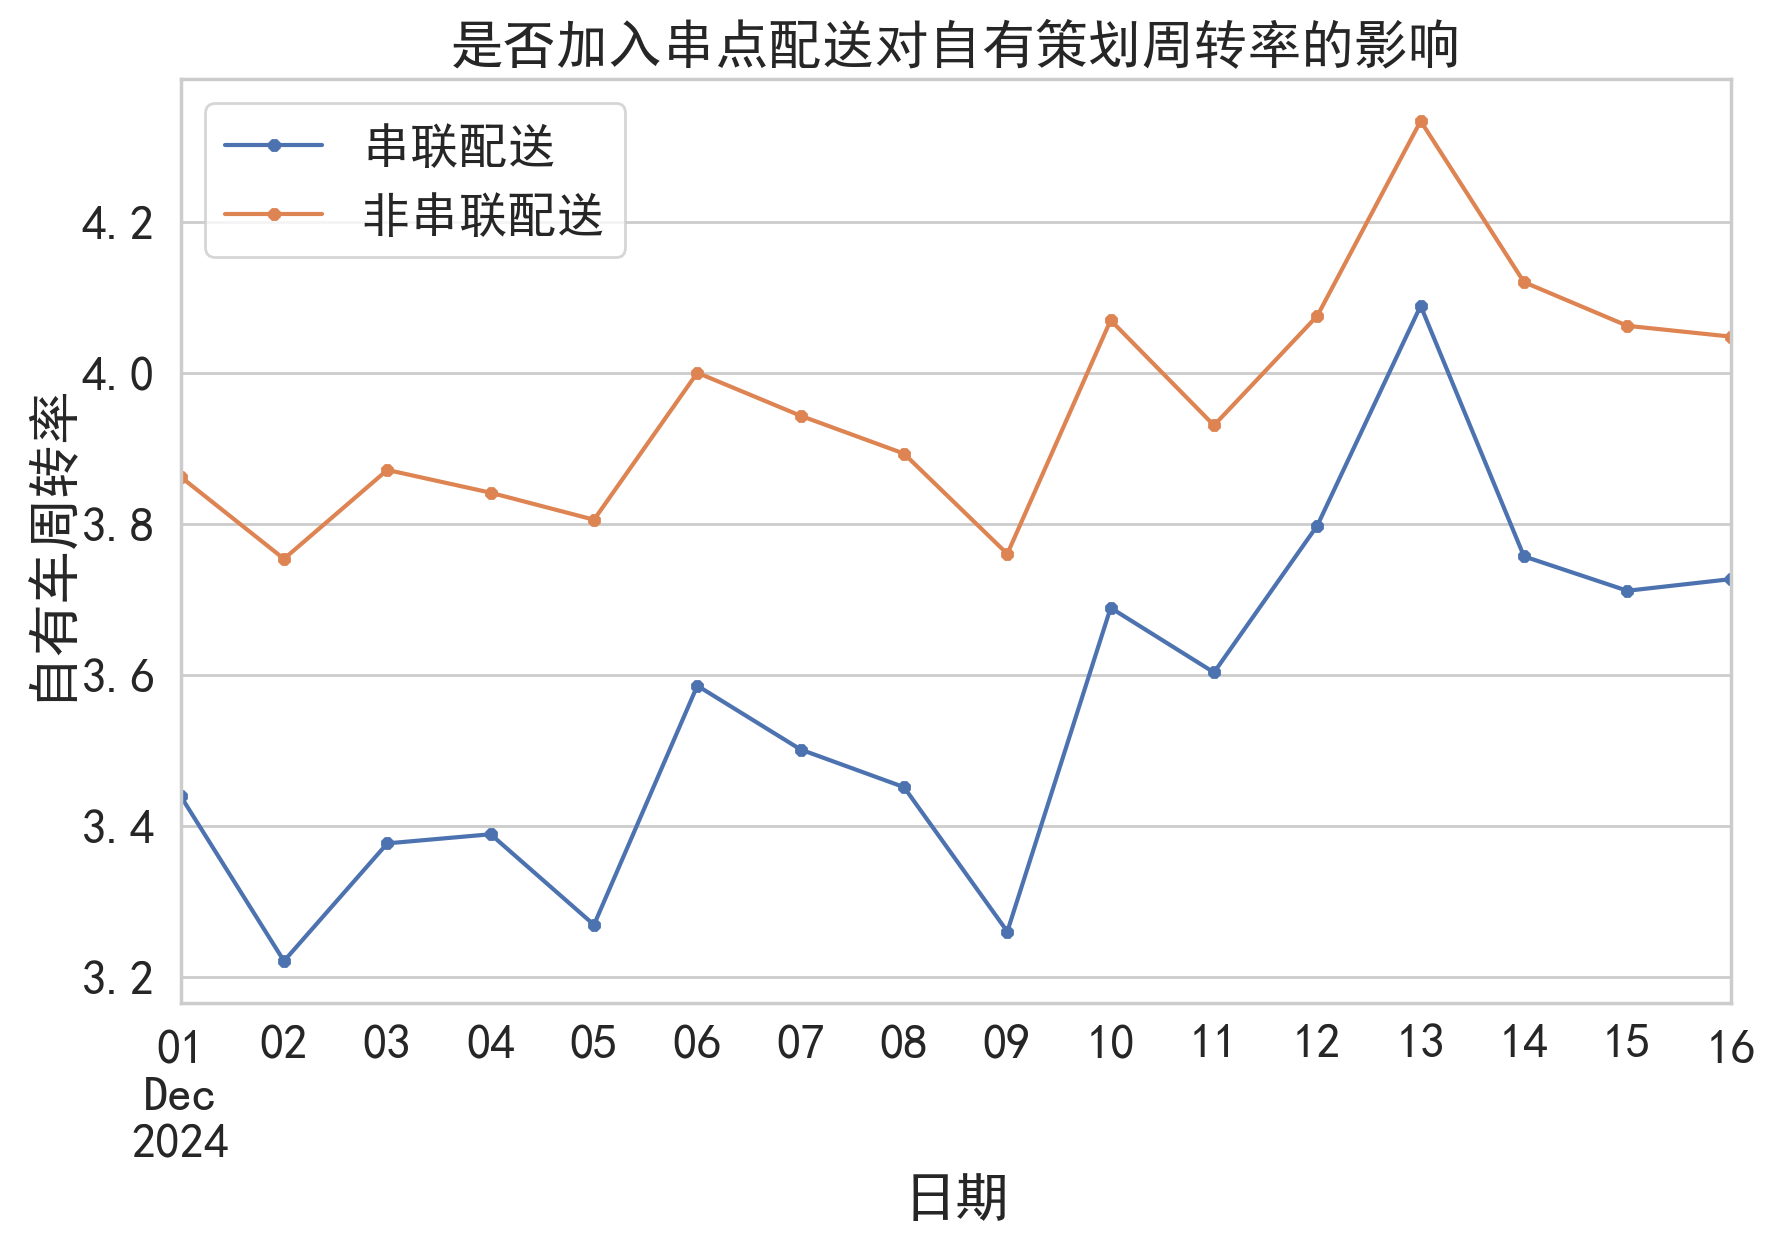

In [94]:
chuan_total_result['自有车周转率'].plot(kind = "line",figsize = (10,6),marker='8',markersize=4,label='串联配送') #颜色,matplotlib
total_result['自有车周转率'].plot(kind = "line",figsize = (10,6),marker='8',markersize=4,label='非串联配送') #颜色,matplotlib
plt.xticks(rotation=0)
plt.xlabel("日期")
plt.ylabel("自有车周转率")
plt.title("是否加入串点配送对自有策划周转率的影响")
plt.legend()
#plt.savefig('问题2\\是否加入串点配送对自有策划周转率的影响.png',dpi=500)
plt.show()

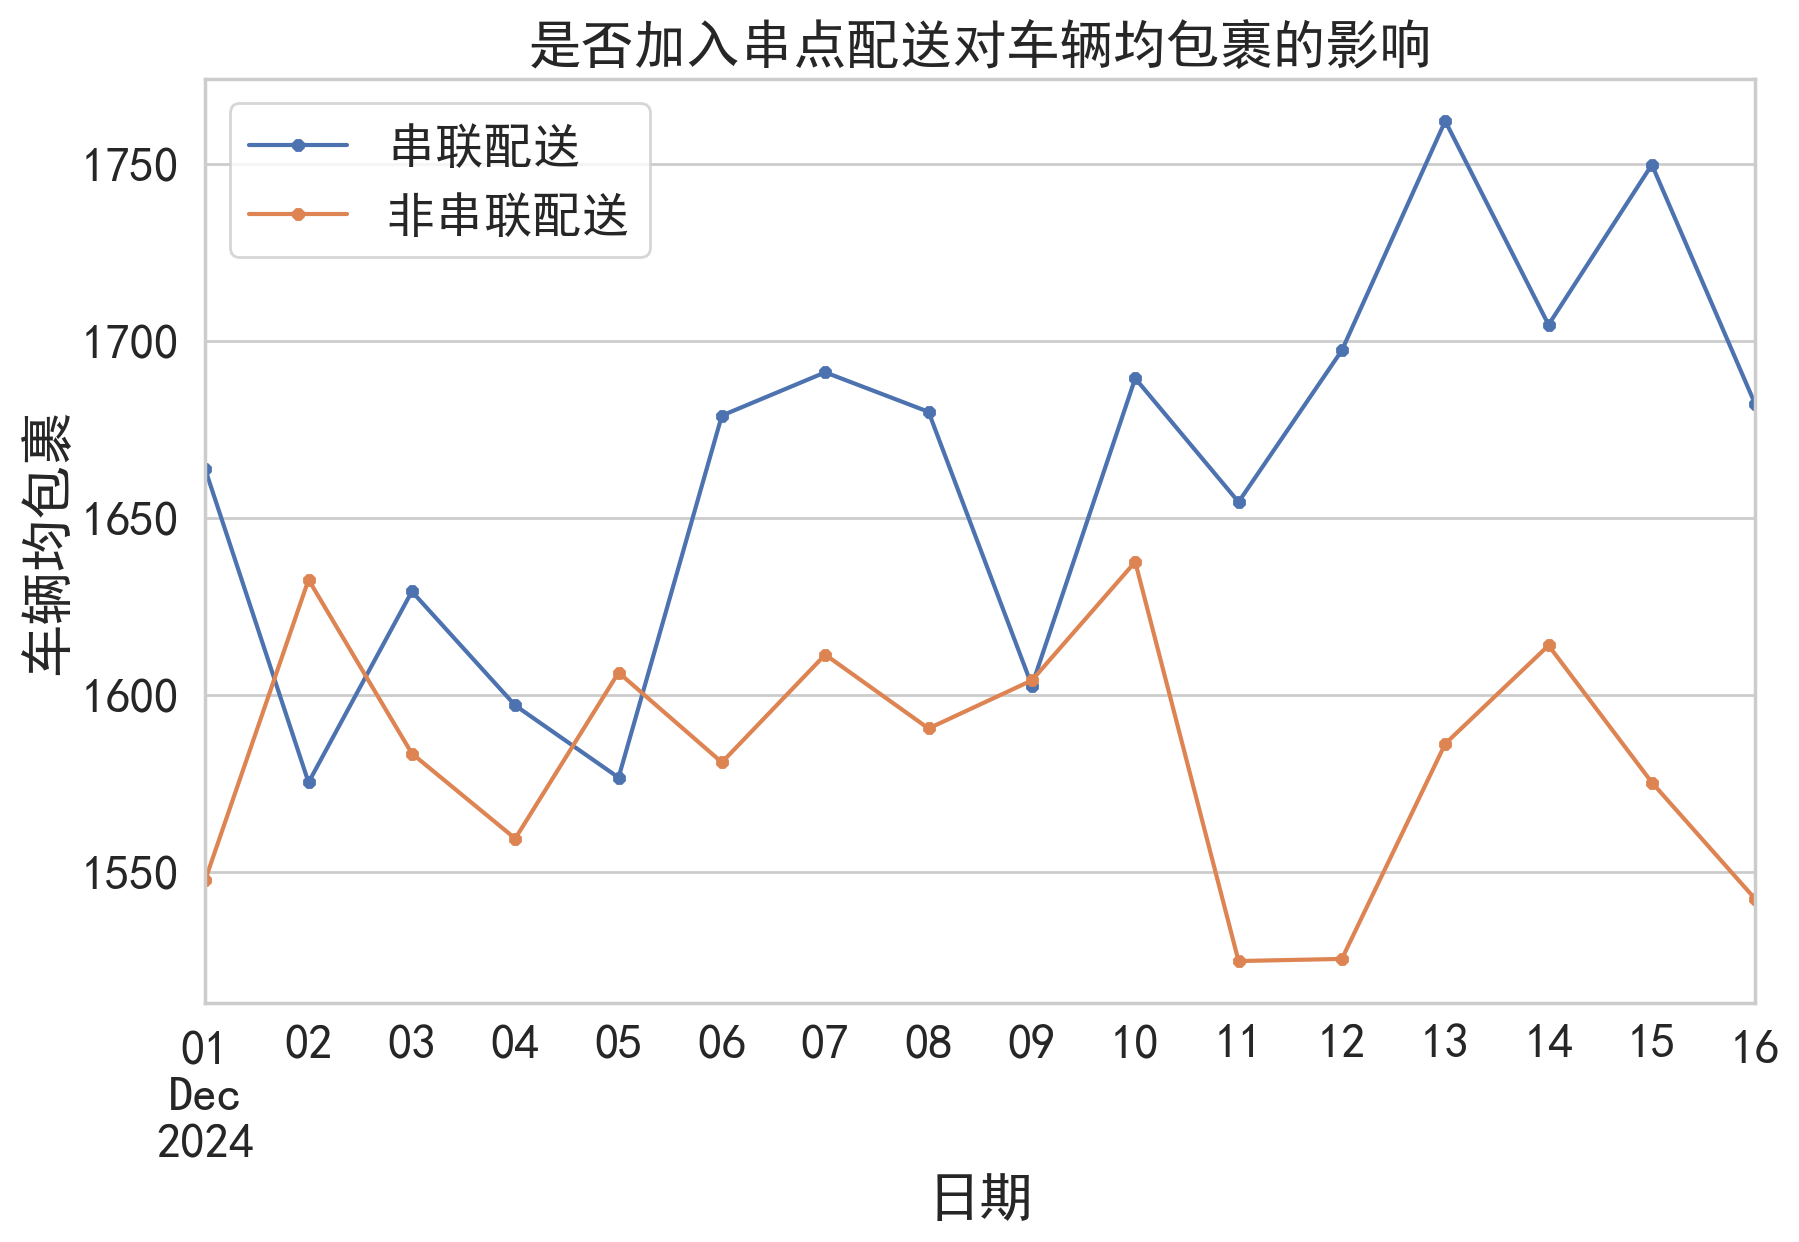

In [96]:
chuan_total_result['车辆均包裹'].plot(kind = "line",figsize = (10,6),marker='8',markersize=4,label='串联配送') #颜色,matplotlib
total_result['车辆均包裹'].plot(kind = "line",figsize = (10,6),marker='8',markersize=4,label='非串联配送') #颜色,matplotlib
plt.xticks(rotation=0)
plt.xlabel("日期")
plt.ylabel("车辆均包裹")
plt.title("是否加入串点配送对车辆均包裹的影响")
plt.legend()
#plt.savefig('问题2\\是否加入串点配送对车辆均包裹的影响.png',dpi=500)
plt.show()

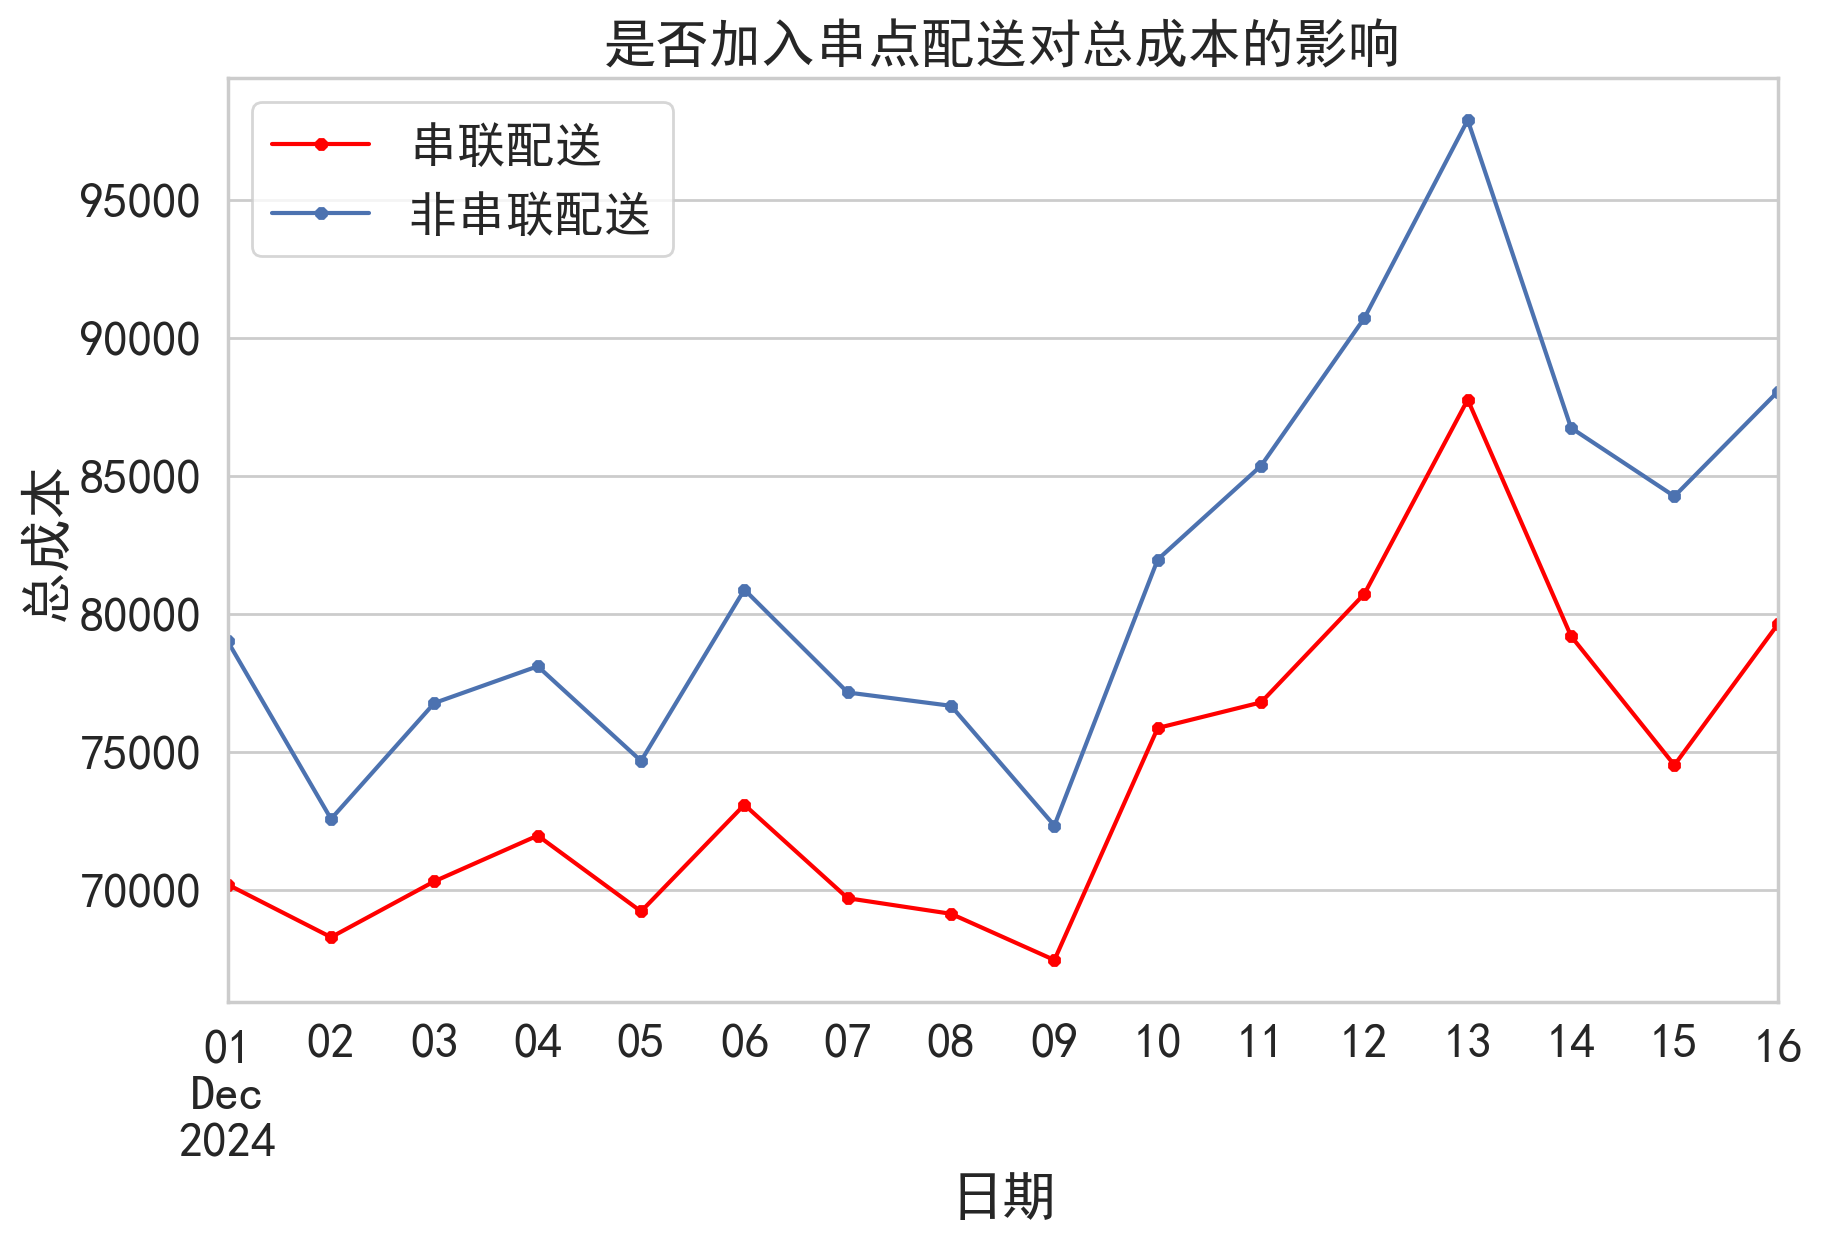

In [97]:
chuan_total_result['总成本'].plot(kind = "line",figsize = (10,6),color='red',marker='8',markersize=4,label='串联配送') #颜色,matplotlib
total_result['总成本'].plot(kind = "line",figsize = (10,6),marker='8',markersize=4,label='非串联配送') #颜色,matplotlib
plt.xticks(rotation=0)
plt.xlabel("日期")
plt.ylabel("总成本")
plt.title("是否加入串点配送对总成本的影响")
plt.legend()
#plt.savefig('问题2\\是否加入串点配送对总成本的影响.png',dpi=500)
plt.show()

#### 可以看到,串联配送的结果是很好的